# 06 - PyTorch with fastai

**fastai** is a high-level library built on PyTorch. For tabular data it provides:
- `TabularPandas`: takes a DataFrame and applies preprocessing steps ("procs"). We use `Normalize`, which standardises every input column with the training statistics automatically.
- `tabular_learner`: builds an MLP with batch normalisation and dropout already included.
- `lr_find`: tries many learning rates and suggests a good one.
- `fit_one_cycle`: trains with the **one-cycle policy**. The learning rate first increases and then decreases during training, which usually trains faster and more stably than a fixed learning rate.

fastai doesn't scale the targets, so they are standardised with `features.scale` (training statistics). As in notebook 05, the final model is trained with 3 seeds.

In [1]:
import sys
import time
import warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from fastai.tabular.all import TabularPandas, Normalize, RegressionBlock, tabular_learner, set_seed

from src import config, features, evaluate, plots

plots.setup()
pd.set_option("display.precision", 4)
df = features.load_dataset()
Y_COLS = [f"y_{t}" for t in config.TARGETS]

## 1. Model

In [2]:
def train_fastai(train_df, val_df, cont_names, layers, lr, epochs, seed=config.SEED):
    set_seed(seed, reproducible=True)
    frame = pd.concat([train_df, val_df])
    splits = (list(range(len(train_df))), list(range(len(train_df), len(frame))))
    to = TabularPandas(frame, procs=[Normalize], cont_names=cont_names, y_names=Y_COLS,
                       y_block=RegressionBlock(), splits=splits)
    dls = to.dataloaders(bs=64, device=torch.device("cpu"))
    learn = tabular_learner(dls, layers=layers, n_out=3)
    with learn.no_bar(), learn.no_logging():
        learn.fit_one_cycle(epochs, lr)
    return learn


def predict_fastai(learn, X):
    with learn.no_bar():
        preds, _ = learn.get_preds(dl=learn.dls.test_dl(X))
    return preds.numpy()


def make_frames(data, scaled):
    """DataFrames with the raw inputs and the standardised targets."""
    frames = {}
    for part in ["train", "val"]:
        frame = data[part]["X"].copy()
        frame[Y_COLS] = scaled[part][1]
        frames[part] = frame
    return frames

## 2. Learning rate finder (experiment C)

`lr_find` trains for a few batches while increasing the learning rate exponentially, and records the loss. A good learning rate is in the steep, falling part of the curve, before the loss blows up.

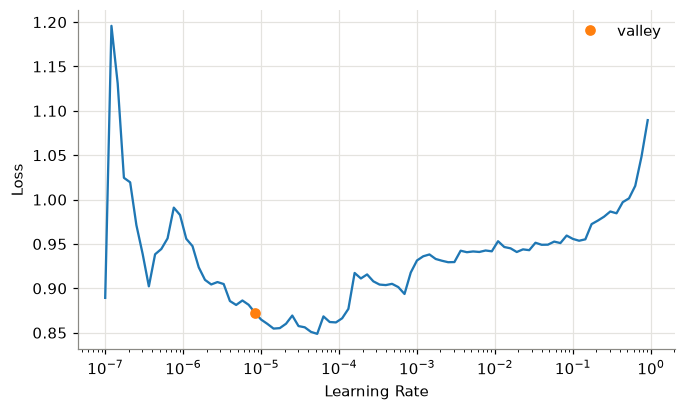

Suggested learning rate (valley): 1e-05


In [3]:
data, mode = features.get_experiment(df, "C")
scaled, _, _ = features.scale(data)
frames = make_frames(data, scaled)
learn = train_fastai(frames["train"], frames["val"], list(data["train"]["X"].columns), [200, 100], 1e-3, 1)
with learn.no_bar():
    suggestion = learn.lr_find()
plt.gcf().set_size_inches(7, 4)
plots.save(plt.gcf(), "06_fastai_lr_find")
plt.show()
print("Suggested learning rate (valley):", round(suggestion.valley, 5))

**Observations**
- The loss curve is noisy and fairly flat (between 0.85 and 0.95) for learning rates from 10⁻⁶ to 10⁻², and the "valley" suggestion is very low (10⁻⁵). Normally the loss falls clearly over a range of learning rates. Here it barely improves at any of them, which is another sign that there is little to learn.
- With 10⁻⁵ the network would need a very large number of epochs, so 10⁻³ and 10⁻² were tried in the tuning instead.

## 3. Tuning on the validation set (seed 42)

In [4]:
configs = [{"layers": layers, "lr": lr, "epochs": epochs}
           for layers in [[200, 100], [64, 32]]
           for lr in [1e-3, 1e-2]
           for epochs in [10, 30]]

best_config, tuning_rows = {}, []
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    scaled, _, unscale_y = features.scale(data)
    frames = make_frames(data, scaled)
    cont_names = list(data["train"]["X"].columns)
    for cfg in configs:
        learn = train_fastai(frames["train"], frames["val"], cont_names, **cfg)
        val_pred = evaluate.to_level(unscale_y(predict_fastai(learn, data["val"]["X"])), data["val"]["today"], mode)
        tuning_rows.append({"experiment": exp, **cfg,
                            "val RMSE (avg)": evaluate.average_rmse(data["val"]["future"], val_pred)})
    rows = [r for r in tuning_rows if r["experiment"] == exp]
    best = min(rows, key=lambda r: r["val RMSE (avg)"])
    best_config[exp] = {k: best[k] for k in ["layers", "lr", "epochs"]}
pd.DataFrame(tuning_rows)

,experiment,layers,lr,epochs,val RMSE (avg)
0,A,"[200, 100]",0.001,10,0.6498
1,A,"[200, 100]",0.001,30,0.6061
2,A,"[200, 100]",0.010,10,0.3873
3,A,"[200, 100]",0.010,30,0.4487
4,A,"[64, 32]",0.001,10,0.5572
5,A,"[64, 32]",0.001,30,0.5007
6,A,"[64, 32]",0.010,10,0.4239
7,A,"[64, 32]",0.010,30,0.3688
8,B,"[200, 100]",0.001,10,0.1908
9,B,"[200, 100]",0.001,30,0.2095


In [5]:
pd.DataFrame(best_config).T

,layers,lr,epochs
A,"[64, 32]",0.01,30
B,"[64, 32]",0.001,10
C,"[64, 32]",0.001,10


## 4. Final models: 3 seeds per experiment

In [6]:
all_metrics, times = [], []
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    scaled, _, unscale_y = features.scale(data)
    frames = make_frames(data, scaled)
    cont_names = list(data["train"]["X"].columns)
    for seed in config.SEEDS:
        start = time.time()
        learn = train_fastai(frames["train"], frames["val"], cont_names, seed=seed, **best_config[exp])
        if exp == "C":
            times.append(time.time() - start)
        if exp == "C" and seed == config.SEED:
            losses_c = pd.DataFrame([list(v[:2]) for v in learn.recorder.values], columns=["train", "valid"])
        pred_level = evaluate.to_level(unscale_y(predict_fastai(learn, data["test"]["X"])), data["test"]["today"], mode)
        evaluate.save_predictions("fastai", exp, seed, data["test"], pred_level)
        m = evaluate.evaluate(data["test"]["future"], pred_level, data["test"]["today"])
        all_metrics.append(m.assign(experiment=exp, seed=seed).reset_index())
        if exp == "C" and seed == config.SEED:
            learn_c, unscale_c = learn, unscale_y

metrics = pd.concat(all_metrics)
summary = metrics.groupby(["experiment", "target"])[["RMSE", "MAE", "R2", "R2_change", "skill_vs_naive", "direction_acc"]]
order = ["1M", "5Y", "30Y"]
summary.mean().reindex(order, level=1).round(4)

RMSE     MAE      R2  R2_change  skill_vs_naive  \
experiment target                                                      
A          1M      0.6992  0.6709 -0.0049   -21.8397         -3.7618   
           5Y      0.2576  0.2122  0.4132    -2.6817         -0.8683   
           30Y     0.5158  0.4759 -0.6840   -24.0423         -3.6439   
B          1M      0.1634  0.0837  0.9453    -0.2426         -0.1131   
           5Y      0.1558  0.1219  0.7944    -0.2900         -0.1296   
           30Y     0.1342  0.1064  0.9006    -0.4775         -0.2084   
C          1M      0.1672  0.0808  0.9429    -0.2985         -0.1388   
           5Y      0.1446  0.1102  0.8244    -0.1019         -0.0484   
           30Y     0.1204  0.0955  0.9203    -0.1846         -0.0843   

                   direction_acc  
experiment target                 
A          1M             0.5264  
           5Y             0.4937  
           30Y            0.4609  
B          1M             0.5108  
           5Y             0.4900  
           30Y            0.4762  
C          1M             0.5196  
           5Y             0.4922  
           30Y            0.4703

In [7]:
summary.std()[["RMSE", "skill_vs_naive"]].reindex(order, level=1).round(4)

RMSE  skill_vs_naive
experiment target                        
A          1M      0.0727          0.4954
           5Y      0.0722          0.5234
           30Y     0.2467          2.2212
B          1M      0.0108          0.0732
           5Y      0.0177          0.1286
           30Y     0.0107          0.0967
C          1M      0.0073          0.0498
           5Y      0.0025          0.0181
           30Y     0.0007          0.0067

In [8]:
evaluate.save_run_info("fastai", {"train_seconds": float(np.mean(times)),
                                  "lines_of_code": evaluate.count_lines(train_fastai) + evaluate.count_lines(predict_fastai),
                                  "hyperparameters": 4,
                                  "tuning_combinations": len(configs)})

**Observations**
- Very similar to Keras. **Experiment A** fails (skill −0.9 to −3.8). **B and C** come close to naive but are still worse.
- **Experiment C** is the best for the 5Y (−0.048) and 30Y (−0.084), but the 1M is −0.14.
- Validation chose the smaller network ([64, 32]) and only **10 epochs** for B and C: the less the network trains, the better it does on new data.
- In experiment C fastai is more stable across seeds than Keras (standard deviation of skill 0.007-0.05, against 0.05-0.19). This may come from the batch normalisation and the one-cycle schedule.
- Direction accuracy is 47-52%.
- **Training curve:** the training loss falls from 1.21 to 0.83, but the validation loss stays between 4.5 and 5.2 the whole time. The network learns the training years without getting any better on 2022.

## 5. Training curve (experiment C, seed 42)

fastai's `Recorder` stores the training and validation loss after every epoch (`learn.recorder.values`).

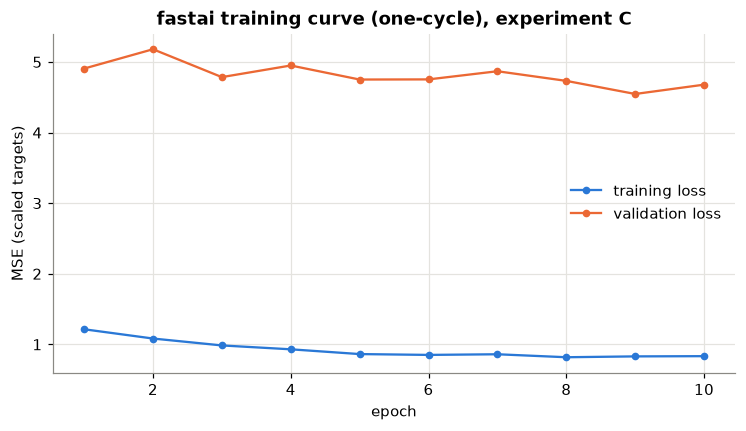

,train,valid
0,1.214,4.906
1,1.083,5.180
2,0.985,4.785
3,0.930,4.950
4,0.863,4.751
5,0.851,4.753
6,0.860,4.869
7,0.818,4.732
8,0.830,4.547
9,0.833,4.679


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
epochs = np.arange(1, len(losses_c) + 1)
ax.plot(epochs, losses_c["train"], color=plots.BLUE, marker="o", markersize=4, label="training loss")
ax.plot(epochs, losses_c["valid"], color=plots.ORANGE, marker="o", markersize=4, label="validation loss")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE (scaled targets)")
ax.set_title("fastai training curve (one-cycle), experiment C")
ax.legend()
plots.save(fig, "06_fastai_training_curve")
plt.show()
losses_c.round(3)

## 6. Permutation feature importance (experiment C)

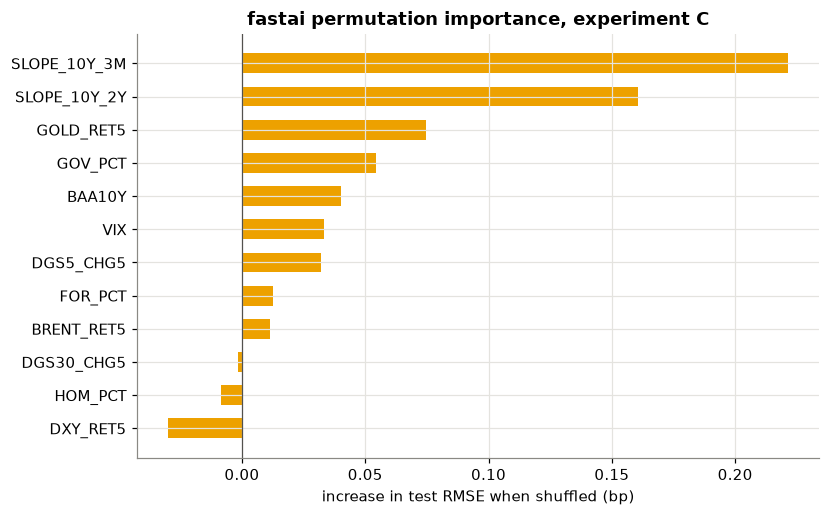

In [10]:
data_c, _ = features.get_experiment(df, "C")

def predict_level(X):
    return evaluate.to_level(unscale_c(predict_fastai(learn_c, X)), data_c["test"]["today"], "change")

importance = evaluate.permutation_importance(predict_level, data_c["test"]["X"], data_c["test"]["future"])
evaluate.save_importance("fastai", importance, "permutation_rmse_increase")

fig, ax = plt.subplots(figsize=(8, 5))
top = importance.head(12).iloc[::-1] * 100
ax.barh(top.index, top.values, color=plots.MODEL_COLORS["fastai"], height=0.6)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("increase in test RMSE when shuffled (bp)")
ax.set_title("fastai permutation importance, experiment C")
plots.save(fig, "06_fastai_importance")
plt.show()

**Observations**
- The two slope features (10Y-3M and 10Y-2Y) matter most, the same as for linear regression and in XGBoost's SHAP plot, followed by the gold return.
- The increases are still small (at most 0.22 bp), but larger than for Keras, so the fastai network uses its inputs a bit more.